# PS-20: Lung and Colon Cancer Histopathology (LC25000)

**Student:** [Your name]  
**Register number:** [Your register number]  
**Goal:** classify images into five LC25000 tissue classes.

> Start by setting `DATA_DIR` below to the faculty-provided dataset folder. This notebook does not invent results: run every cell to generate plots and test metrics from your data. LC25000 contains augmented images derived from a smaller set of originals, so a random image split may put near-duplicates in both train and test. If original-image IDs are unavailable, report this as a limitation and do not present the score as an estimate of real-world generalisation.


## 1. Imports and reproducibility

In [1]:
import os, random, pathlib, json, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)


/Users/darshan/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow: 2.16.2


## 2. Point to the dataset and inspect class counts

Set `DATA_DIR` to the directory containing the five class folders. Common folder names are supported below; edit `CLASS_DIRS` if your faculty copy uses different names. Do not point it at a folder that mixes unrelated files.

In [2]:
DATA_DIR = pathlib.Path("/Users/darshan/Downloads/lung_colon_image_set")
CLASS_DIRS = {
    "lung_aca": "Lung adenocarcinoma",
    "lung_scc": "Lung squamous cell carcinoma",
    "lung_n": "Benign lung tissue",
    "colon_aca": "Colon adenocarcinoma",
    "colon_n": "Benign colon tissue",
}
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
if not DATA_DIR.exists(): raise FileNotFoundError(f"Set DATA_DIR to the dataset folder; not found: {DATA_DIR}")
paths, labels = [], []
for folder, label in CLASS_DIRS.items():
    matches = list(DATA_DIR.rglob(folder))
    class_dir = next((p for p in matches if p.is_dir()), None)
    if class_dir is None: raise FileNotFoundError(f"Could not find class folder {folder!r} under {DATA_DIR}; edit CLASS_DIRS")
    files = sorted(p for p in class_dir.iterdir() if p.suffix.lower() in EXTS)
    print(f"{label}: {len(files)}")
    paths.extend(map(str, files)); labels.extend([folder] * len(files))
if not paths: raise ValueError("No images found")
class_names = list(CLASS_DIRS.keys()); class_to_id = {c:i for i,c in enumerate(class_names)}
y = np.array([class_to_id[x] for x in labels], dtype=np.int32)


Lung adenocarcinoma: 5000
Lung squamous cell carcinoma: 5000
Benign lung tissue: 5000
Colon adenocarcinoma: 5000
Benign colon tissue: 5000


## 3. View sample images

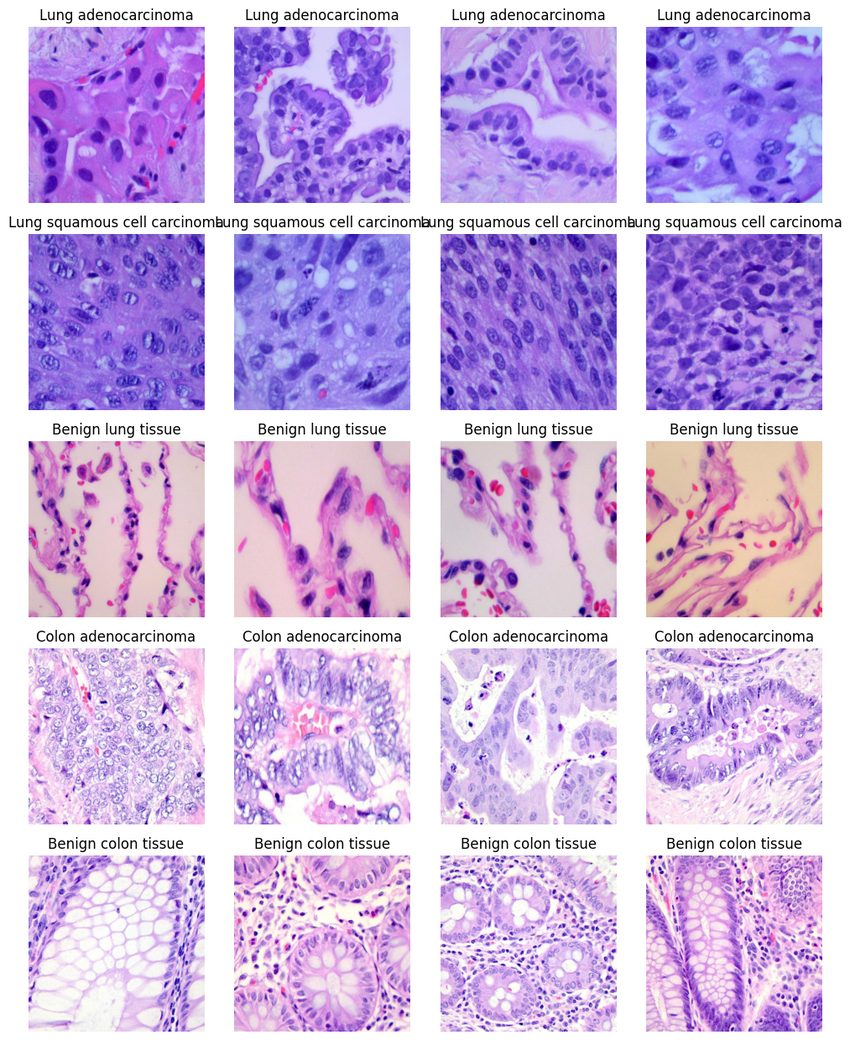

In [3]:
from PIL import Image
fig, axes = plt.subplots(len(class_names), 4, figsize=(10, 2.5*len(class_names)))
for row, cname in enumerate(class_names):
    candidates = [i for i, lab in enumerate(labels) if lab == cname][:4]
    for col in range(4):
        ax = axes[row, col]
        if col < len(candidates):
            im = Image.open(paths[candidates[col]]).convert("RGB")
            ax.imshow(im); ax.set_title(CLASS_DIRS[cname])
        ax.axis("off")
plt.tight_layout()


## 4. Train, validation, and test split

This baseline uses stratified image-level splits (70/15/15). **This does not prevent augmented relatives of the same original image from crossing splits.** If your dataset copy has source-image IDs, replace this with a group split before reporting results. The lab brief calls out near-duplicate leakage explicitly.

In [4]:
idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED, stratify=y[temp_idx])
print("Images:", len(train_idx), "train /", len(val_idx), "validation /", len(test_idx), "test")


Images: 17500 train / 3750 validation / 3750 test


## 5. Input pipeline and training-only augmentation

In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.08),
])

def make_ds(indices, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.array(paths)[indices], y[indices]))
    if training: ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training: ds = ds.map(lambda x, lab: (augment(x, training=True), lab), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_idx, True)
val_ds = make_ds(val_idx)
test_ds = make_ds(test_idx)


## 6. Transfer-learning model and training

In [6]:
# MobileNetV2 is used as a compact ImageNet-pretrained baseline.
base = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks)
training_seconds = time.time() - start
print(f"Training time: {training_seconds/60:.1f} minutes")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 78s 141ms/step - accuracy: 0.8209 - loss: 0.5142 - val_accuracy: 0.9509 - val_loss: 0.1426
Epoch 2/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 84s 154ms/step - accuracy: 0.9583 - loss: 0.1176 - val_accuracy: 0.9613 - val_loss: 0.1088
Epoch 3/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 87s 158ms/step - accuracy: 0.9643 - loss: 0.0943 - val_accuracy: 0.9661 - val_loss: 0.0925
Epoch 4/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 91s 166ms/step - accuracy: 0.9682 - loss: 0.0855 - val_accuracy: 0.9635 - val_loss: 0.0990
Epoch 5/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 99s 180ms/step - accuracy: 0.9729 - loss: 0.0760 - val_accuracy: 0.9688 - val_loss: 0.0820
Epoch 6/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 102s 187ms/step - accuracy: 0.9753 - loss: 0.0688 - val_accuracy: 0.9803 - val_loss: 0.0557
Epoch 7/12
547/547 ━━━━━━━━━━━━━━━━━━━━ 105s 192ms/step - accuracy: 0.9761 - loss: 0.0626 - val_accuracy: 0.9792 - val_loss: 0.0564
Epoch 8/12
547/547 ━━━━━━━━━━━━━

## 7. Learning curves

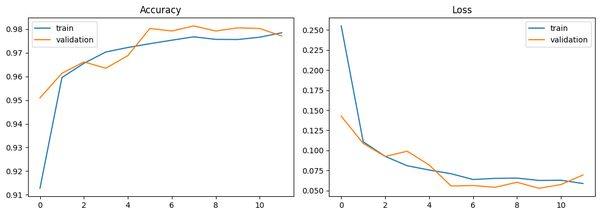

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["accuracy"], label="train"); axes[0].plot(history.history["val_accuracy"], label="validation"); axes[0].set_title("Accuracy"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train"); axes[1].plot(history.history["val_loss"], label="validation"); axes[1].set_title("Loss"); axes[1].legend()
plt.tight_layout()


## 8. One-time test evaluation

118/118 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step
Test accuracy: 0.9827
Macro F1: 0.9827
                              precision    recall  f1-score   support

         Lung adenocarcinoma     0.9741    0.9547    0.9643       750
Lung squamous cell carcinoma     0.9507    0.9773    0.9638       750
          Benign lung tissue     1.0000    1.0000    1.0000       750
        Colon adenocarcinoma     0.9893    0.9893    0.9893       750
         Benign colon tissue     1.0000    0.9920    0.9960       750

                    accuracy                         0.9827      3750
                   macro avg     0.9828    0.9827    0.9827      3750
                weighted avg     0.9828    0.9827    0.9827      3750



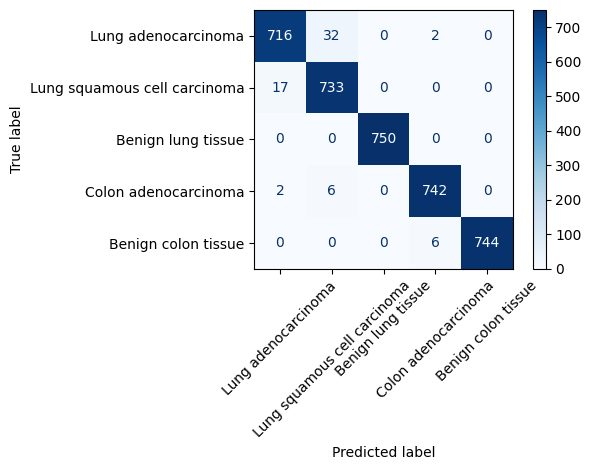

In [8]:
probs = model.predict(test_ds, verbose=1)
y_true = y[test_idx]
y_pred = probs.argmax(axis=1)
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print(classification_report(y_true, y_pred, labels=np.arange(len(class_names)), target_names=[CLASS_DIRS[c] for c in class_names], digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
ConfusionMatrixDisplay(cm, display_labels=[CLASS_DIRS[c] for c in class_names]).plot(xticks_rotation=45, cmap="Blues", values_format="d")
plt.tight_layout()


## 9. Inspect at least four misclassified test examples

Misclassified: 65 of 3750


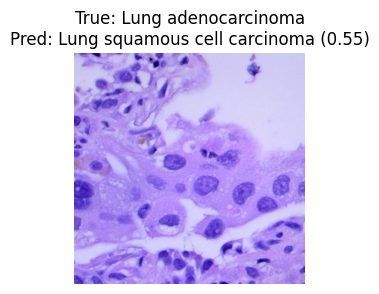

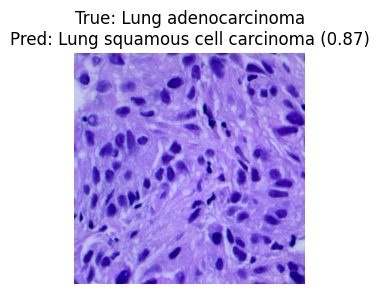

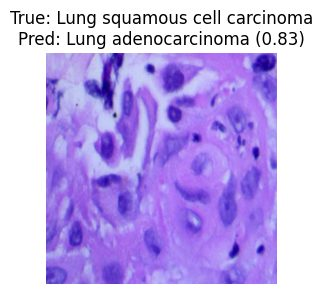

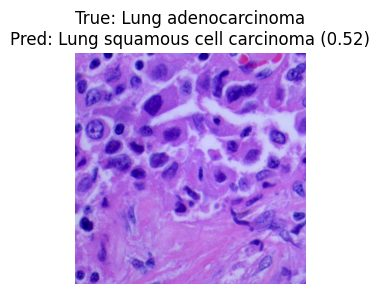

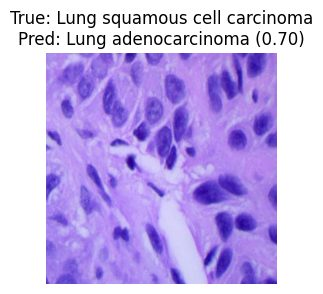

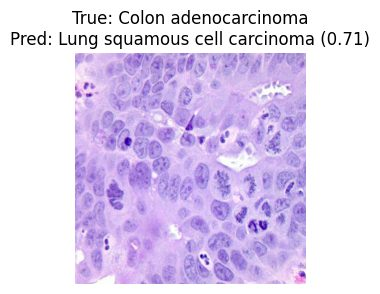

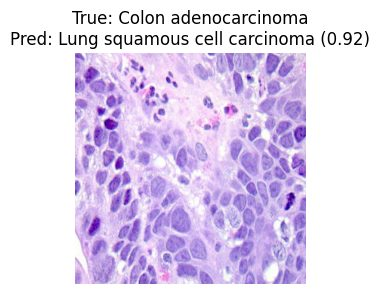

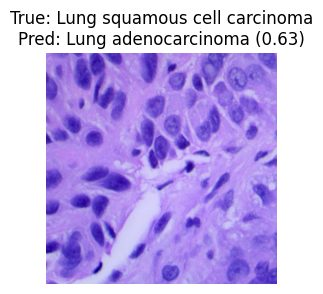

In [9]:
errors = np.where(y_true != y_pred)[0]
print("Misclassified:", len(errors), "of", len(y_true))
for j in errors[:8]:
    original_idx = test_idx[j]
    im = Image.open(paths[original_idx]).convert("RGB")
    plt.figure(figsize=(3,3)); plt.imshow(im); plt.axis("off")
    plt.title(f"True: {CLASS_DIRS[class_names[y_true[j]]]}\nPred: {CLASS_DIRS[class_names[y_pred[j]]]} ({probs[j].max():.2f})")
    plt.show()


## 10. Save model and record caveats

In [10]:
model.save("PS20_mobilenetv2.keras")
print("Saved PS20_mobilenetv2.keras")


Saved PS20_mobilenetv2.keras
